# Support Vector Machines and Kernels

*Решение упражнений*

# Цели обучения
- Применить метод опорных векторов (SVM) — популярный алгоритм, используемый для задач классификации
- Распознать сходство SVM с логистической регрессией
- Вычислить функцию потерь для SVM
- Применить регуляризацию в SVM и изучить советы по получению нелинейной классификации с помощью SVM

## Введение
В этих упражнениях мы будем использовать набор данных о качестве вина. Этот набор данных содержит различные химические свойства вина, такие как кислотность, сахар, pH и алкоголь. Он также содержит метрику качества (от 3 до 9, где наивысший балл означает лучшее качество) и цвет (красное или белое). Имя файла: `Wine_Quality_Data.csv`.

In [1]:
# Импорт необходимых библиотек
from __future__ import print_function
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

from sklearn.svm import LinearSVC, SVC
from sklearn.kernel_approximation import Nystroem
from sklearn.linear_model import SGDClassifier
from sklearn.preprocessing import MinMaxScaler
from sklearn.pipeline import Pipeline

sns.set(style="ticks")
np.random.seed(42)

## Вопрос 1
* Импорт данных.
* Создайте целевую переменную `y` как колонка 1/0, где 1 означает красное вино.
* Создайте парный график для набора данных.
* Создайте диаграмму столбцов, которая отображает корреляцию между каждой колонкой и `y`.
* Выберите 2 поля с наибольшей корреляцией (используя значения абсолютной корреляции) и создайте `X`.
* Используйте MinMaxScaler для масштабирования `X`. Обратите внимание, что вывод будет np.array. Сделайте его снова DataFrame и соответственно переименуйте столбцы.

In [2]:
# Загружаем данные
data = pd.read_csv('Wine_Quality_Data.csv')
print(data.shape)
data.head()

(6497, 13)


,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,quality,color
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,red
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,red
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,red
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red


In [3]:
# Целевая переменная: 1 - красное вино, 0 - белое вино
y = (data['color'] == 'red').astype(int)
y.value_counts()

color
0    4898
1    1599
Name: count, dtype: int64

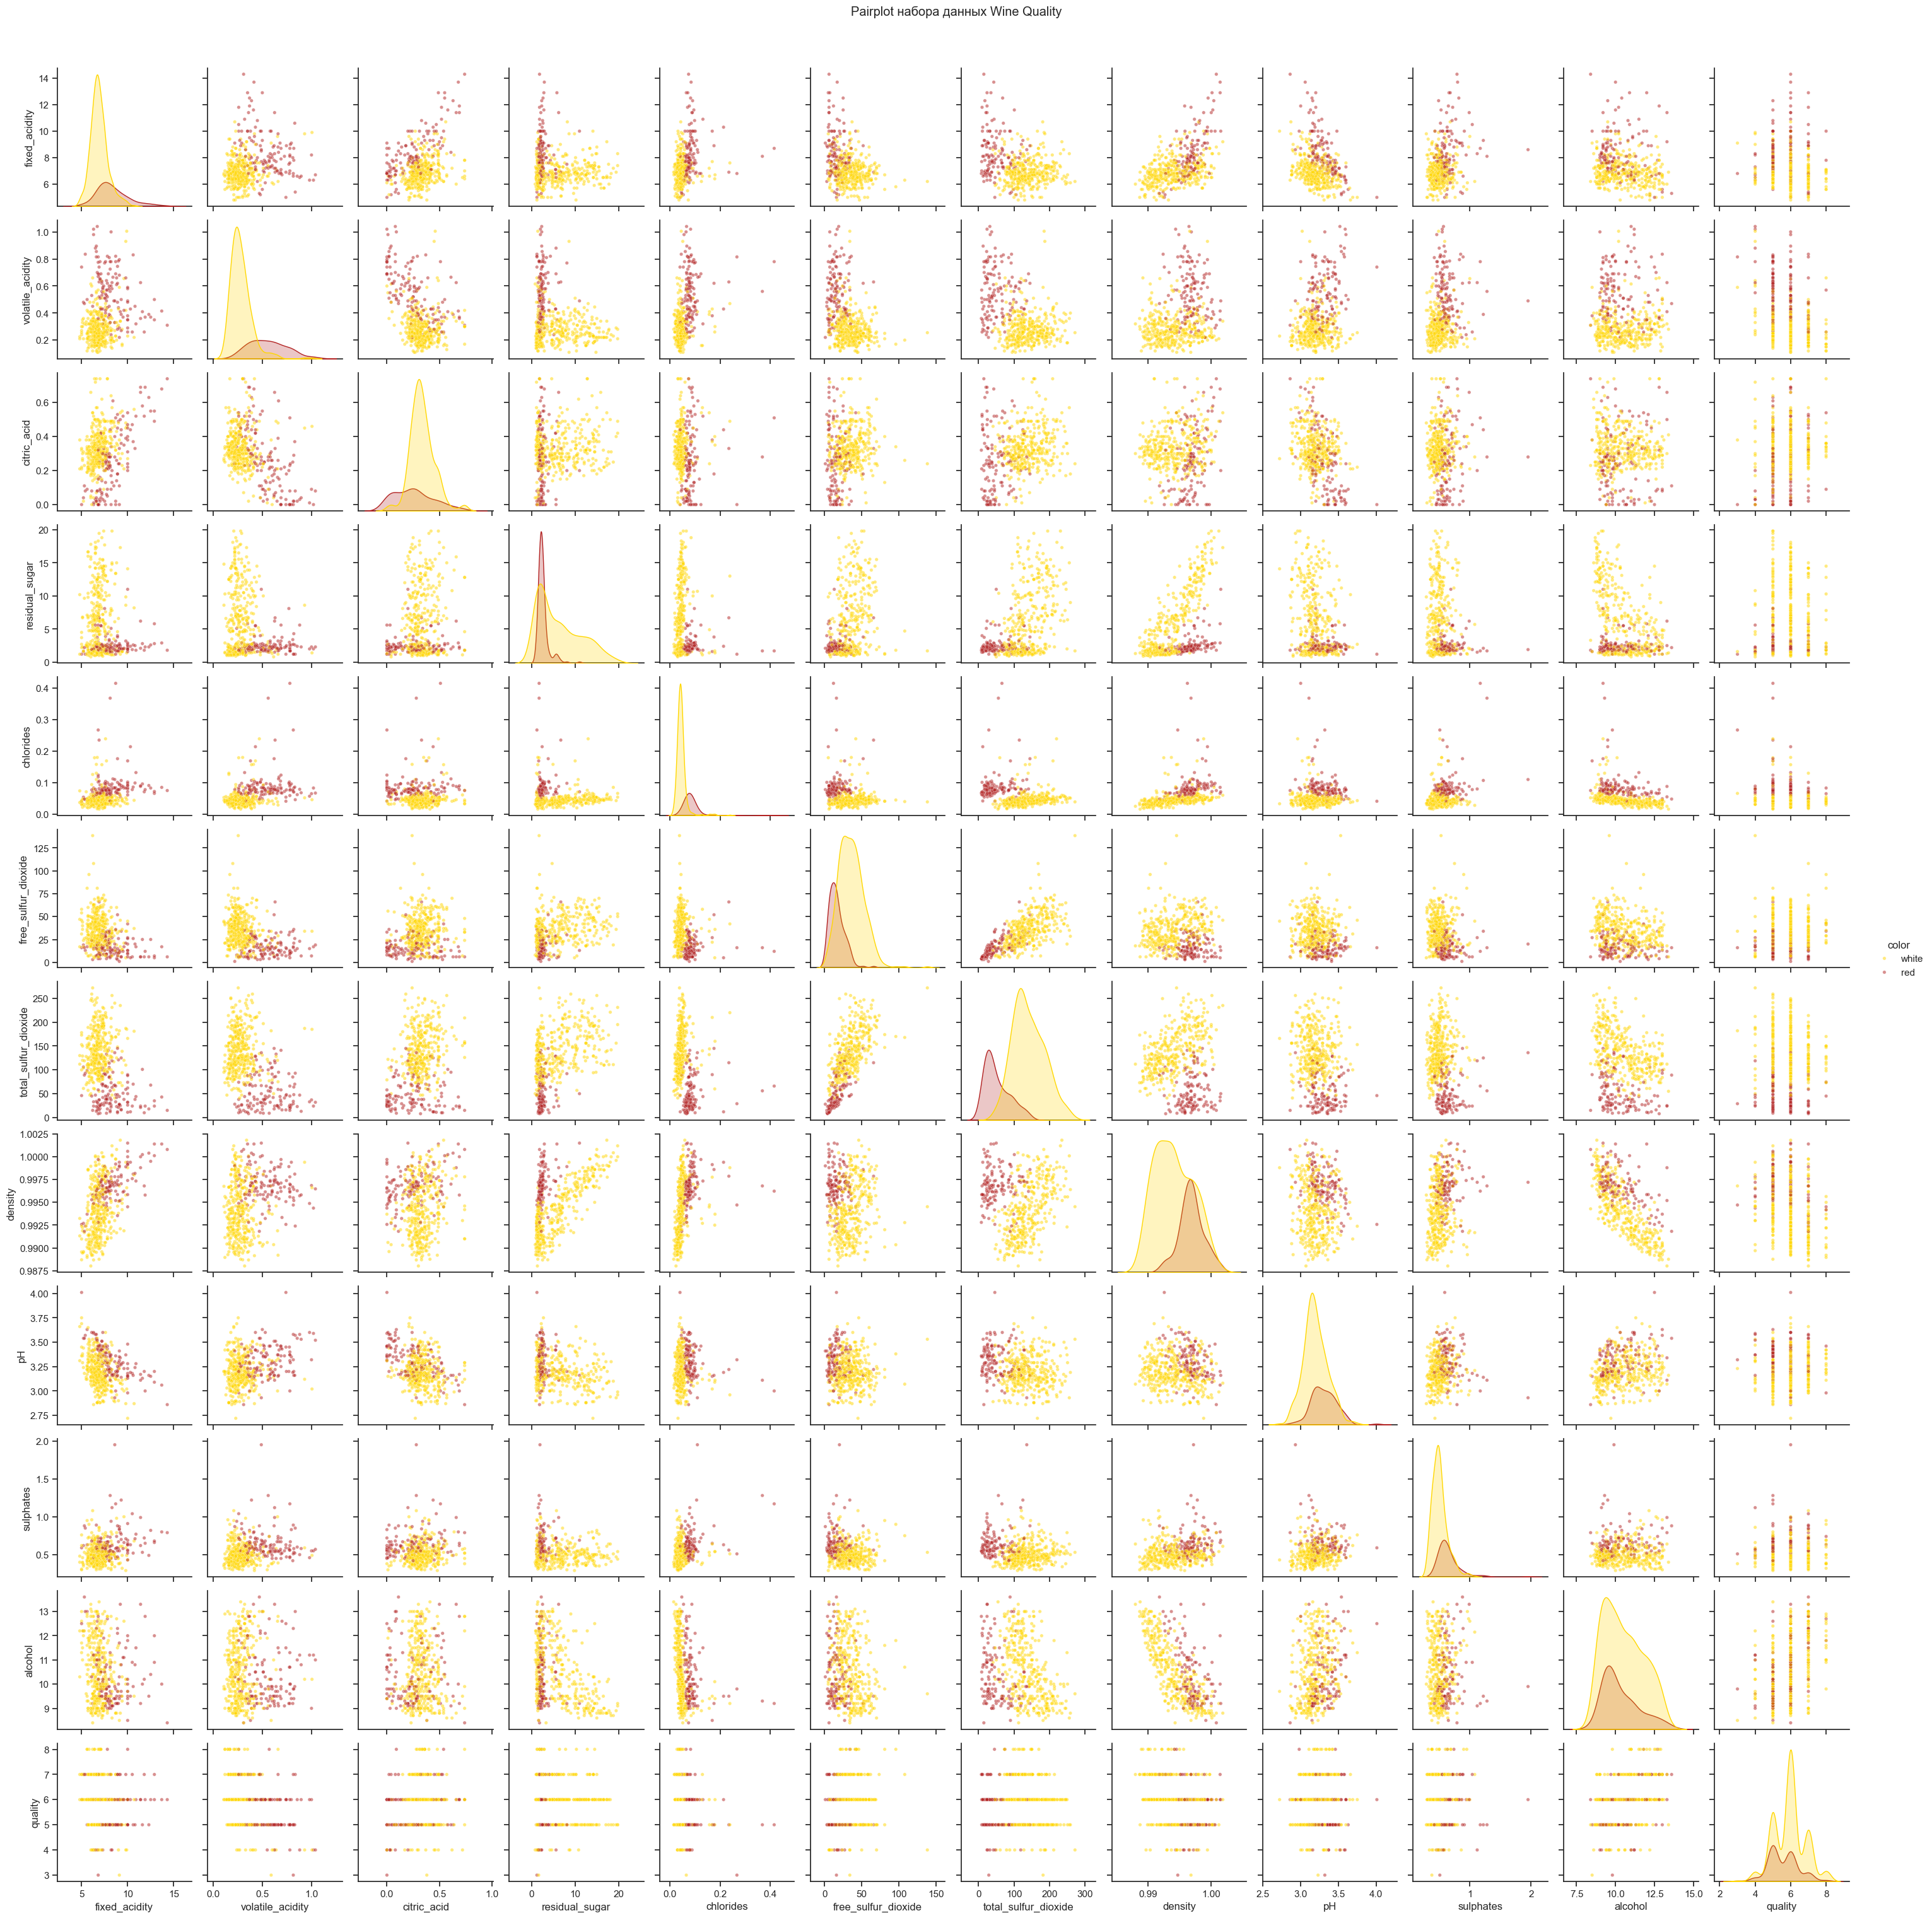

In [4]:
# Парный график (pairplot) по числовым признакам, с раскраской по цвету вина
# (для скорости используем подвыборку, т.к. полный набор данных большой)
sample = data.sample(500, random_state=42)
sns.pairplot(sample, hue='color', palette={'red': 'firebrick', 'white': 'gold'},
             plot_kws={'alpha': 0.5, 's': 15})
plt.suptitle('Pairplot набора данных Wine Quality', y=1.02)
plt.show()

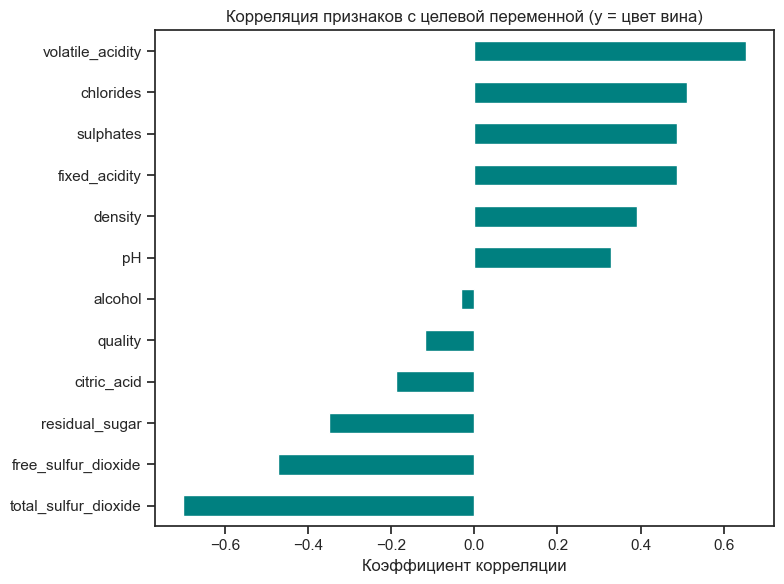

total_sulfur_dioxide   -0.700357
free_sulfur_dioxide    -0.471644
residual_sugar         -0.348821
citric_acid            -0.187397
quality                -0.119323
alcohol                -0.032970
pH                      0.329129
density                 0.390645
fixed_acidity           0.486740
sulphates               0.487218
chlorides               0.512678
volatile_acidity        0.653036
Name: y, dtype: float64

In [5]:
# Корреляция каждого числового признака с целевой переменной y
numeric_data = data.drop(columns=['color']).copy()
numeric_data['y'] = y
correlations = numeric_data.corr()['y'].drop('y').sort_values()

fig, ax = plt.subplots(figsize=(8, 6))
correlations.plot(kind='barh', ax=ax, color='teal')
ax.set_title('Корреляция признаков с целевой переменной (y = цвет вина)')
ax.set_xlabel('Коэффициент корреляции')
plt.tight_layout()
plt.show()

correlations

In [6]:
# Выбираем 2 признака с наибольшей абсолютной корреляцией с y
top_2_features = correlations.abs().sort_values(ascending=False).index[:2].tolist()
print('Выбранные признаки:', top_2_features)

X = data[top_2_features]
X.head()

Выбранные признаки: ['total_sulfur_dioxide', 'volatile_acidity']


,total_sulfur_dioxide,volatile_acidity
0,34.0,0.70
1,67.0,0.88
2,54.0,0.76
3,60.0,0.28
4,34.0,0.70


In [7]:
# Масштабируем X с помощью MinMaxScaler
scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(X)

# Результат - numpy array, превращаем обратно в DataFrame с исходными именами столбцов
X = pd.DataFrame(X_scaled, columns=top_2_features)
X.describe()

,total_sulfur_dioxide,volatile_acidity
count,6497.000000,6497.000000
mean,0.252868,0.173111
std,0.130235,0.109758
min,0.000000,0.000000
25%,0.163594,0.100000
50%,0.258065,0.140000
75%,0.345622,0.213333
max,1.000000,1.000000


## Вопрос 2

Цель этого вопроса - посмотреть на границу принятия решения классификатора LinearSVC для данного набора данных. Ознакомьтесь с [этим примером](http://scikit-learn.org/stable/auto_examples/svm/plot_iris.html#sphx-glr-auto-examples-svm-plot-iris-py) в документации sklearn.

* Установите классификатор линейной векторной машины поддержки на `X`, `y`.
* Выберите 300 образцов из `X`. Получите соответствующее значение `y`. Сохраните их в переменных `X_color` и `y_color`.
* Измените `y_color` таким образом, чтобы вместо 1 было указано значение «красный», а вместо 0 - «желтый».
* Рассеянный график для столбцов `X_color`.
* Нарисуйте поверхность решения с помощью `ax.contourf`.

In [8]:
# Обучаем LinearSVC на всех данных X, y
LSVC = LinearSVC(random_state=42, max_iter=10000)
LSVC.fit(X, y)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo random number generation for shuffling the data forthe dual coordinate descent (if ``dual=True``). When ``dual=False`` theunderlying implementation of :class:`LinearSVC` is not random and``random_state`` has no effect on the results.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"max_iter max_iter: int, default=1000The maximum number of iterations to be run.",10000
,"penalty penalty: {'l1', 'l2'}, default='l2'Specifies the norm used in the penalization. The 'l2'penalty is the standard used in SVC. The 'l1' leads to ``coef_``vectors that are sparse.",'l2'
,"loss loss: {'hinge', 'squared_hinge'}, default='squared_hinge'Specifies the loss function. 'hinge' is the standard SVM loss(used e.g. by the SVC class) while 'squared_hinge' is thesquare of the hinge loss. The combination of ``penalty='l1'``and ``loss='hinge'`` is not supported.",'squared_hinge'
,"dual dual: ""auto"" or bool, default=""auto""Select the algorithm to either solve the dual or primaloptimization problem. Prefer dual=False when n_samples > n_features.`dual=""auto""` will choose the value of the parameter automatically,based on the values of `n_samples`, `n_features`, `loss`, `multi_class`and `penalty`. If `n_samples` < `n_features` and optimizer supportschosen `loss`, `multi_class` and `penalty`, then dual will be set to True,otherwise it will be set to False... versionchanged:: 1.3 The `""auto""` option is added in version 1.3 and will be the default in version 1.5.",'auto'
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive.For an intuitive visualization of the effects of scalingthe regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"multi_class multi_class: {'ovr', 'crammer_singer'}, default='ovr'Determines the multi-class strategy if `y` contains more thantwo classes.``""ovr""`` trains n_classes one-vs-rest classifiers, while``""crammer_singer""`` optimizes a joint objective over all classes.While `crammer_singer` is interesting from a theoretical perspectiveas it is consistent, it is seldom used in practice as it rarely leadsto better accuracy and is more expensive to compute.If ``""crammer_singer""`` is chosen, the options loss, penalty and dualwill be ignored.",'ovr'
,"fit_intercept fit_intercept: bool, default=TrueWhether or not to fit an intercept. If set to True, the feature vectoris extended to include an intercept term: `[x_1, ..., x_n, 1]`, where1 corresponds to the intercept. If set to False, no intercept will beused in calculations (i.e. data is expected to be already centered).",True
,"intercept_scaling intercept_scaling: float, default=1.0When `fit_intercept` is True, the instance vector x becomes ``[x_1,..., x_n, intercept_scaling]``, i.e. a ""synthetic"" feature with aconstant value equal to `intercept_scaling` is appended to the instancevector. The intercept becomes intercept_scaling * synthetic featureweight. Note that liblinear internally penalizes the intercept,treating it like any other term in the feature vector. To reduce theimpact of the regularization on the intercept, the `intercept_scaling`parameter can be set to a value greater than 1; the higher the value of`intercept_scaling`, the lower the impact of regularization on it.Then, the weights become `[w_x_1, ..., w_x_n,w_intercept*intercept_scaling]`, where `w_x_1, ..., w_x_n` representthe feature weights and the intercept weight is scaled by`intercept_scaling`. This scaling allows the intercept term to have adifferent regularization behavior compared to the other features.",1
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to ``class_weight[i]*C`` forSVC. If not given, all classes are s

In [9]:
# Берём случайную подвыборку из 300 образцов для наглядного графика
np.random.seed(42)
sample_idx = np.random.choice(X.index, size=300, replace=False)

X_color = X.loc[sample_idx]
y_color = y.loc[sample_idx]

# Заменяем 1 -> 'red', 0 -> 'yellow'
y_color = y_color.map({1: 'red', 0: 'yellow'})
y_color.value_counts()

color
yellow    229
red        71
Name: count, dtype: int64

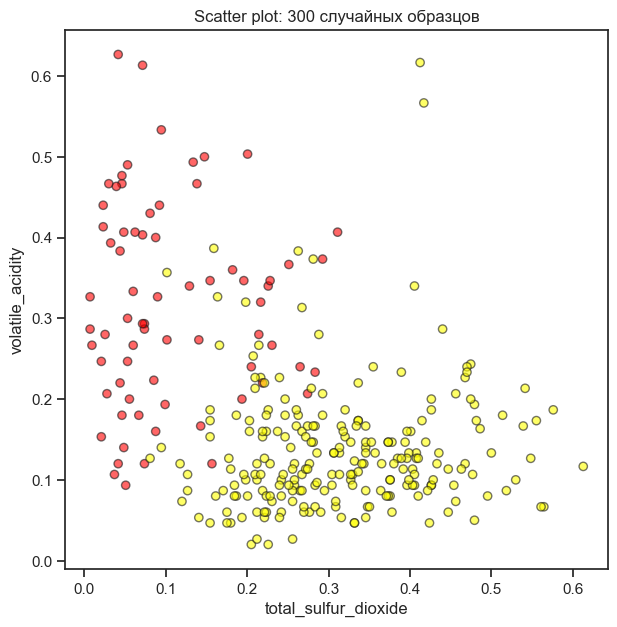

In [10]:
# Точечный график (scatter) исходных точек
fig, ax = plt.subplots(figsize=(7, 7))
ax.scatter(X_color.iloc[:, 0], X_color.iloc[:, 1], color=y_color, alpha=0.6, edgecolor='k')
ax.set_xlabel(top_2_features[0])
ax.set_ylabel(top_2_features[1])
ax.set_title('Scatter plot: 300 случайных образцов')
plt.show()

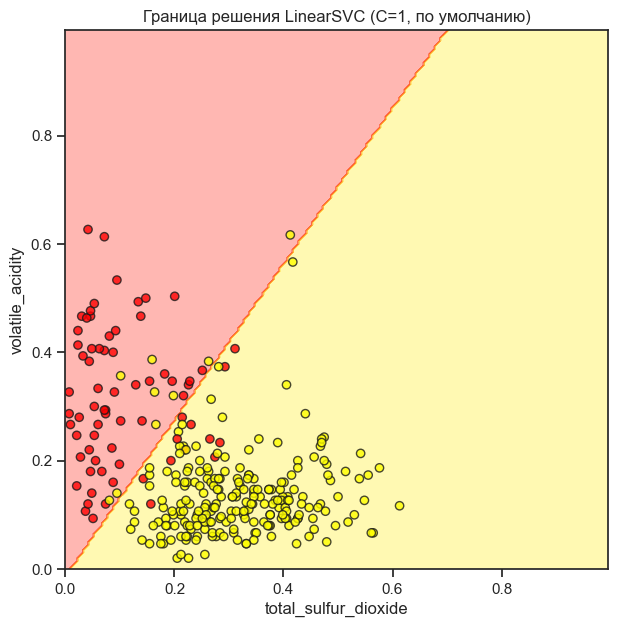

In [11]:
# Строим границу решения LinearSVC поверх точек
fig, ax = plt.subplots(figsize=(7, 7))

x_axis, y_axis = np.arange(0, 1, .005), np.arange(0, 1, .005)
xx, yy = np.meshgrid(x_axis, y_axis)
xx_ravel = xx.ravel()
yy_ravel = yy.ravel()
X_grid = pd.DataFrame([xx_ravel, yy_ravel]).T
X_grid.columns = top_2_features

y_grid_predictions = LSVC.predict(X_grid)
y_grid_predictions = y_grid_predictions.reshape(xx.shape)

ax.contourf(xx, yy, y_grid_predictions, cmap=plt.cm.autumn_r, alpha=.3)
ax.scatter(X_color.iloc[:, 0], X_color.iloc[:, 1], color=y_color, alpha=0.8, edgecolor='k')
ax.set_xlabel(top_2_features[0])
ax.set_ylabel(top_2_features[1])
ax.set_title('Граница решения LinearSVC (C=1, по умолчанию)')
plt.show()

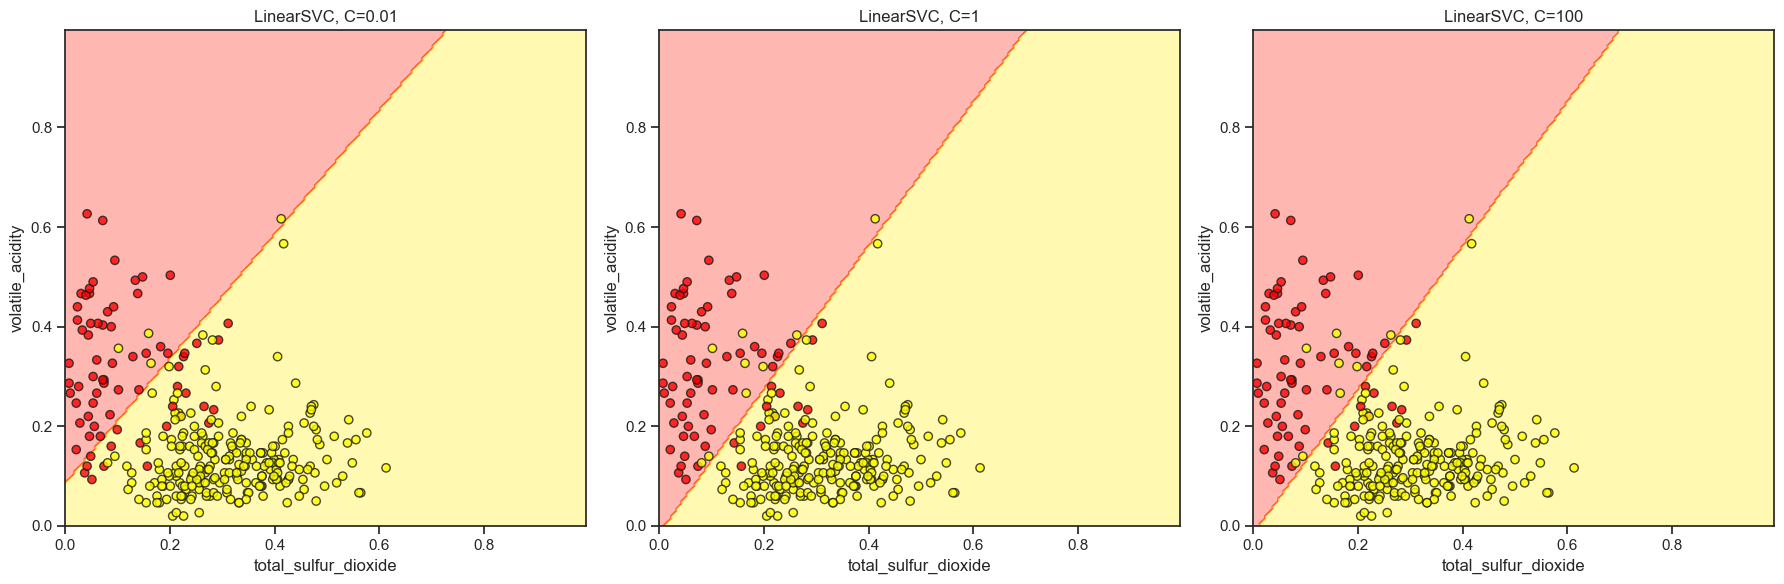

In [12]:
# Экспериментируем с параметром C классификатора LinearSVC
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
Cs_experiment = [0.01, 1, 100]

for c, ax in zip(Cs_experiment, axes):
    model = LinearSVC(random_state=42, C=c, max_iter=10000)
    model.fit(X, y)

    y_grid_predictions = model.predict(X_grid).reshape(xx.shape)
    ax.contourf(xx, yy, y_grid_predictions, cmap=plt.cm.autumn_r, alpha=.3)
    ax.scatter(X_color.iloc[:, 0], X_color.iloc[:, 1], color=y_color, alpha=0.8, edgecolor='k')
    ax.set_title(f'LinearSVC, C={c}')
    ax.set_xlabel(top_2_features[0])
    ax.set_ylabel(top_2_features[1])

plt.tight_layout()
plt.show()

# Вывод: при малых C граница более "мягкая" (больше регуляризации, допускает больше ошибок),
# при больших C модель сильнее старается разделить классы без ошибок на обучающей выборке,
# но для линейно разделимых данных граница меняется не сильно.

## Вопрос 3

Давайте теперь развернём гауссовское ядро SVC и посмотрим, как изменяется граница решения.

* Объединим фрагменты кода из вопроса 2 в одну функцию, которая обучает оценщика на `X`, `y` и строит график с границей решения.
* Для `gamma = [.5, 1, 2, 10]` создадим Gaussian Kernel SVC и нарисуем границу решения.
* При фиксированной `gamma`, для `C = [.1, 1, 10]`, нарисуем границу решения.

In [13]:
def plot_decision_boundary(estimator, X, y, ax=None, title=None, random_state=42):
    """
    Обучает estimator на X, y и строит границу решения.

    Шаги:
    1. Обучить модель (estimator.fit)
    2. Взять случайную выборку из 300 точек X и соответствующих y
    3. Построить сетку (meshgrid), получить предсказания на сетке
    4. Нарисовать границу решения через ax.contourf
    5. Добавить точки выборки поверх scatter-графиком
    """
    # 1. Обучаем переданный оценщик
    estimator.fit(X, y)

    # 2. Берём случайную подвыборку из 300 точек
    rng = np.random.RandomState(random_state)
    sample_idx = rng.choice(X.index, size=300, replace=False)
    X_color = X.loc[sample_idx]
    y_color = y.loc[sample_idx].map({1: 'red', 0: 'yellow'})

    # 3. Строим сетку и получаем предсказания
    x_axis, y_axis = np.arange(0, 1, .005), np.arange(0, 1, .005)
    xx, yy = np.meshgrid(x_axis, y_axis)
    X_grid = pd.DataFrame([xx.ravel(), yy.ravel()]).T
    X_grid.columns = X.columns
    y_grid_predictions = estimator.predict(X_grid).reshape(xx.shape)

    # 4. Рисуем границу решения
    if ax is None:
        fig, ax = plt.subplots(figsize=(6, 6))
    ax.contourf(xx, yy, y_grid_predictions, cmap=plt.cm.autumn_r, alpha=.3)

    # 5. Добавляем точки
    ax.scatter(X_color.iloc[:, 0], X_color.iloc[:, 1], color=y_color, alpha=0.8, edgecolor='k')
    ax.set_xlabel(X.columns[0])
    ax.set_ylabel(X.columns[1])
    if title:
        ax.set_title(title)
    return ax

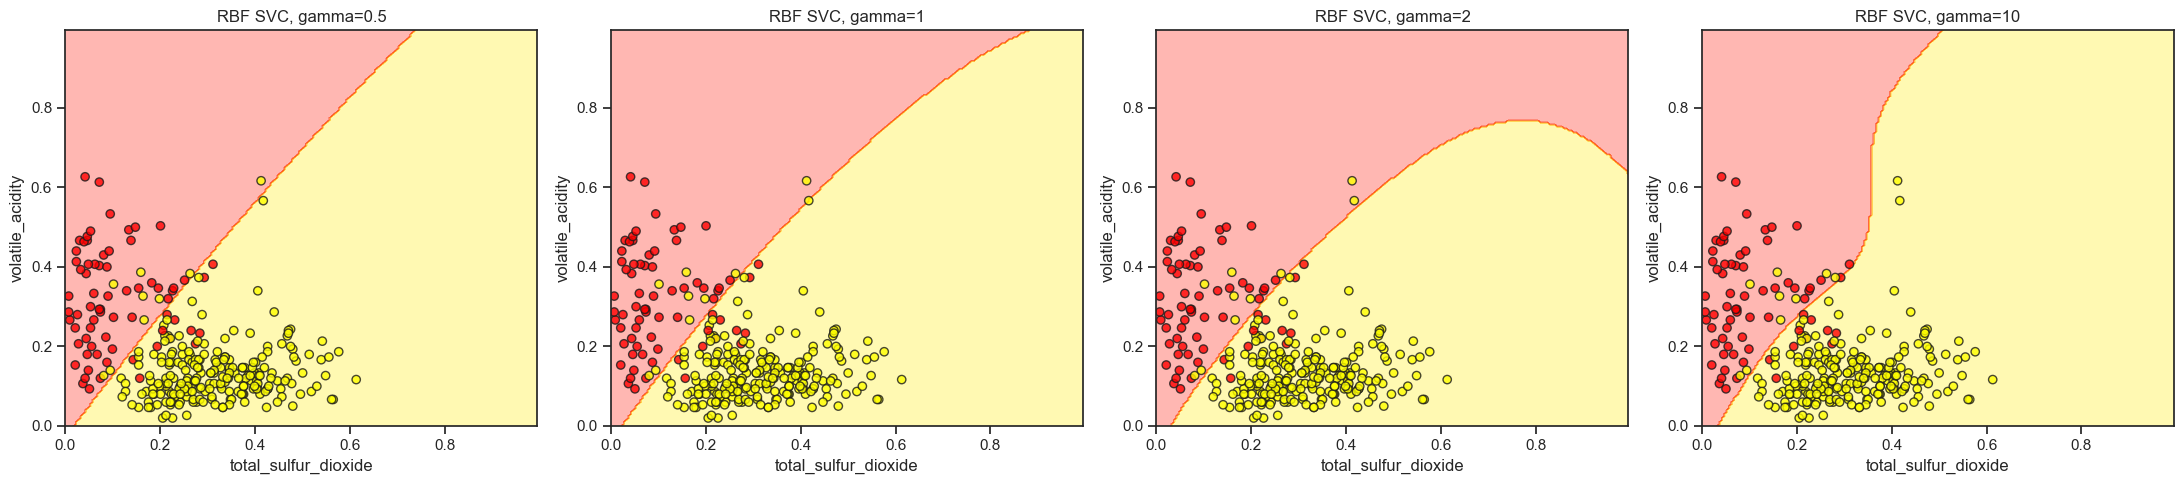

In [14]:
# Границы решения для SVC с ядром RBF при разных значениях gamma (C зафиксирован = 1)
gammas = [.5, 1, 2, 10]

fig, axes = plt.subplots(1, 4, figsize=(22, 5))
for gamma, ax in zip(gammas, axes):
    svc = SVC(kernel='rbf', gamma=gamma, C=1, random_state=42)
    plot_decision_boundary(svc, X, y, ax=ax, title=f'RBF SVC, gamma={gamma}')

plt.tight_layout()
plt.show()

# Вывод: чем больше gamma, тем "уже" и сложнее становится граница решения -
# модель начинает подстраиваться под локальные особенности данных (риск переобучения).

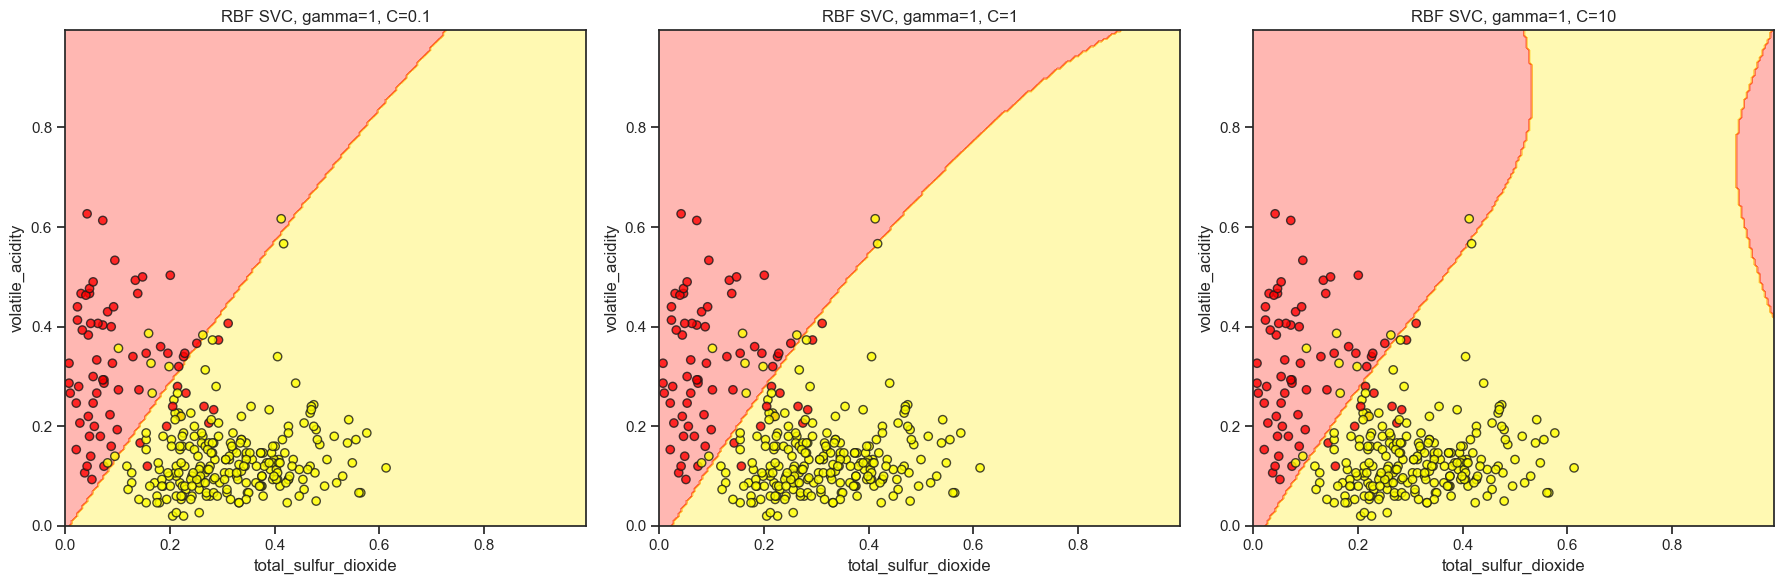

In [15]:
# Границы решения для SVC с ядром RBF при фиксированной gamma=1 и разных значениях C
Cs = [.1, 1, 10]

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for c, ax in zip(Cs, axes):
    svc = SVC(kernel='rbf', gamma=1, C=c, random_state=42)
    plot_decision_boundary(svc, X, y, ax=ax, title=f'RBF SVC, gamma=1, C={c}')

plt.tight_layout()
plt.show()

# Вывод: при малом C (0.1) граница более гладкая и допускает больше ошибок на обучающей выборке
# (сильнее регуляризация). При большом C (10) граница становится более сложной и "подстраивается"
# под обучающие точки сильнее (меньше регуляризация, риск переобучения).

## Вопрос 4

В этом вопросе мы сравним время установки между SVC и Nystroem с ядром RBF.

* Повторно загрузим данные о качестве вина.
* Создадим `y` из `data.color` и `X` из остальных столбцов.
* Используем `%%timeit`, чтобы получить время настройки SVC с ядром RBF.
* Используем `%%timeit` для времени настройки пайплайна Nystroem + SGDClassifier.
* Сделаем 5 копий `X` и `y`, объединим их и сравним время обучения обоих методов на увеличенном наборе данных.

In [16]:
# Повторно загружаем данные
data = pd.read_csv('Wine_Quality_Data.csv')

y = (data['color'] == 'red').astype(int)
X = data.drop(columns=['color'])

print(X.shape, y.shape)
X.head()

(6497, 12) (6497,)


,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [17]:
%%timeit
# Время обучения SVC с ядром RBF на исходных данных
svc = SVC(kernel='rbf')
svc.fit(X, y)

441 ms ± 64.9 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)


In [18]:
%%timeit
# Время обучения пайплайна Nystroem (аппроксимация ядра) + SGDClassifier
nystroem_sgd = Pipeline([
    ('nystroem', Nystroem(kernel='rbf', random_state=42)),
    ('sgd', SGDClassifier(max_iter=1000, tol=1e-3, random_state=42))
])
nystroem_sgd.fit(X, y)

274 ms ± 29.8 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)


In [19]:
# Делаем 5 копий X и y и объединяем их, чтобы увеличить набор данных
X_copy = pd.concat([X] * 5, ignore_index=True)
y_copy = pd.concat([y] * 5, ignore_index=True)

print('Исходный размер:', X.shape, '  Увеличенный размер:', X_copy.shape)

Исходный размер: (6497, 12)   Увеличенный размер: (32485, 12)


In [20]:
%%timeit
# Время обучения SVC (RBF) на увеличенном наборе данных
svc = SVC(kernel='rbf')
svc.fit(X_copy, y_copy)

10.9 s ± 5.21 s per loop (mean ± std. dev. of 7 runs, 1 loop each)


In [21]:
%%timeit
# Время обучения Nystroem + SGDClassifier на увеличенном наборе данных
nystroem_sgd = Pipeline([
    ('nystroem', Nystroem(kernel='rbf', random_state=42)),
    ('sgd', SGDClassifier(max_iter=1000, tol=1e-3, random_state=42))
])
nystroem_sgd.fit(X_copy, y_copy)

250 ms ± 11.7 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)


**Вывод:** на исходном (небольшом) наборе данных разница во времени обучения SVC(kernel='rbf') и
Nystroem+SGDClassifier не очень заметна. Но на увеличенном в 5 раз наборе данных время обучения SVC
растёт значительно быстрее (сложность SVC с ядром растёт примерно квадратично или хуже от числа объектов),
тогда как Nystroem+SGDClassifier масштабируется почти линейно и остаётся быстрым. Это иллюстрирует, почему
для больших наборов данных предпочтительнее использовать аппроксимацию ядра (Nystroem) вместе с линейными
моделями, обучаемыми стохастическим градиентным спуском, вместо точного SVC с ядром.